FEATURE SELECTION METHODS

Why do Feature Selection?
1. It is simpler to maintain
2. Faster to train
3. It improves the models performance

When to do Feature Selection?

We do feature selection before hyperparameter tuning and model selection


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

%matplotlib inline

plt.rcParams["figure.figsize"]= (12,9)

Read The Data

In [4]:
wine_data= load_wine()
wine_df= pd.DataFrame( 
                        data= wine_data.data,
                        columns= wine_data.feature_names
)

In [5]:
wine_df['target']= wine_data.target
wine_df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [6]:
from seaborn import swarmplot

data_to_plot= pd.melt(wine_df[['alcohol','malic_acid','alcalinity_of_ash','target']],
                      id_vars= 'target',
                      var_name= 'features',
                      value_name= 'value')
swarmplot(data= data_to_plot, x= 'features', y='value', hue='target',);

C:\Users\HP\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 8.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


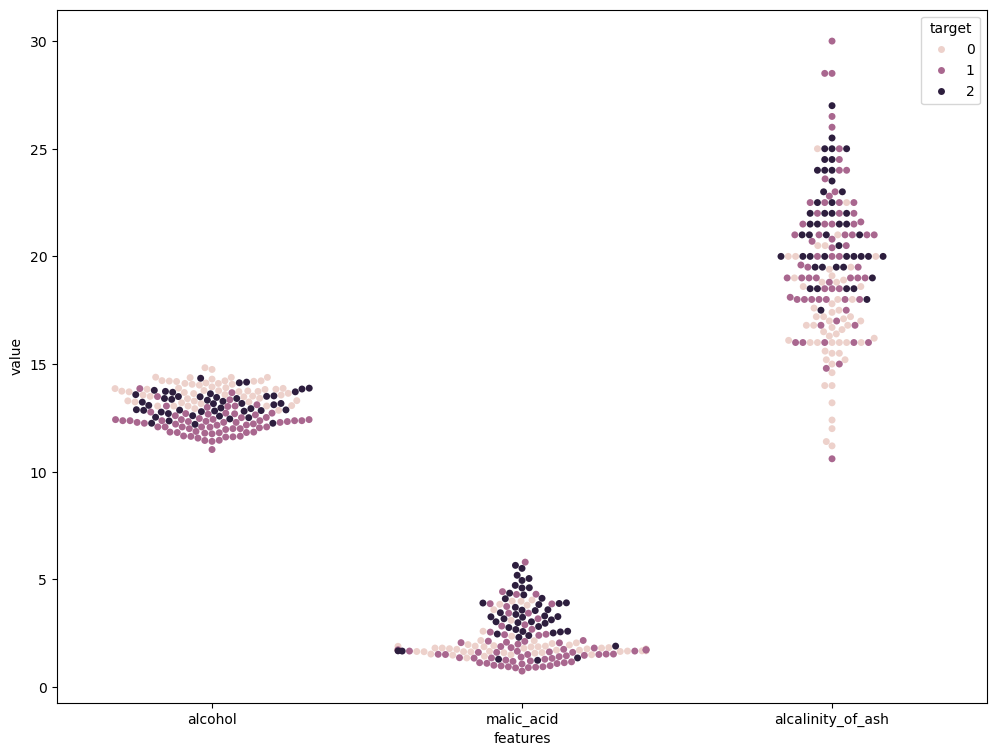

In [7]:
plt.show()

In [8]:
wine_df['target'].value_counts()

target
1    71
0    59
2    48
Name: count, dtype: int64

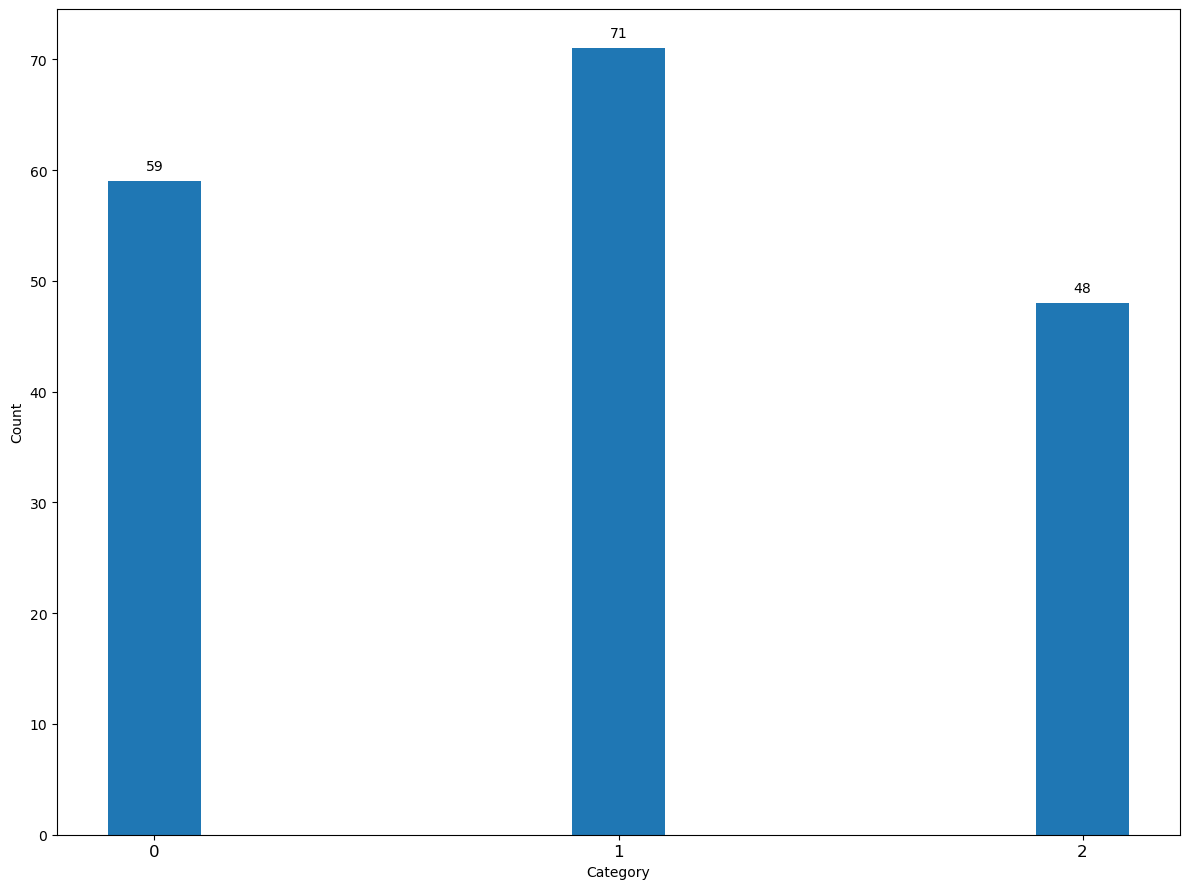

In [9]:
fig, ax= plt.subplots()
x= [0,1,2]
y= [59,71,48]

ax.bar(x,y, width= 0.2)

ax.set_xlabel('Category')
ax.set_ylabel('Count')
ax.set_xticks([0,1,2])
ax.set_xticklabels([0,1,2], fontsize= 12)

for index, value in enumerate(y):
    plt.text(x= int(index), y= value + 1, s= str(value), ha='center')
    
plt.tight_layout()
plt.show()

Train/Test Split

In [11]:
from sklearn.model_selection import train_test_split

x= wine_df.drop(['target'], axis=1)
y= wine_df['target']

x_train,x_test,y_train,y_test= train_test_split(
                                                x,y,
                                                test_size= 0.3,
                                                shuffle= True,
                                                stratify= y,
                                                random_state= 42)

In [12]:
print(x_train.shape)
print(x_test.shape)

(124, 13)
(54, 13)


Baseline Model: Gradient Boosting Classifier With All Features

In [14]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import f1_score

# Initialize classifier using all features
gbc= GradientBoostingClassifier(max_depth= 5, random_state= 42)

# Train classifier using all features
gbc.fit(x_train, y_train)

# Make predictions
preds= gbc.predict(x_test)

# Evaluate the model using the F1_score
f1_score_all= round(f1_score(y_test, preds, average='weighted'),3)

print(f1_score_all)

0.908


1- Variance Threshhold Method

It is a measure of spread from the mean, if the variance is 0, 

then we have a feature with constant value.

if a feature has a variance of 0, then it is likely not predictive

FEATURE SELECTION TECHNIQUES

Variance Threshold

In [17]:
x_train_v1, x_test_v1, y_train_v1, y_test_v1= x_train.copy(), x_test.copy(), y_train.copy(), y_test.copy()

In [18]:
# Calculate the variance of each feature

x_train_v1.var(axis= 0)

alcohol                             0.658341
malic_acid                          1.123507
ash                                 0.072433
alcalinity_of_ash                  11.471279
magnesium                         232.071532
total_phenols                       0.393226
flavanoids                          0.912299
nonflavanoid_phenols                0.013873
proanthocyanins                     0.335108
color_intensity                     5.669722
hue                                 0.052891
od280/od315_of_diluted_wines        0.470021
proline                         94906.710923
dtype: float64

In [19]:
# From the above, we see that our data is not properly scaled hence we need to scale our data before making a decision

from sklearn.preprocessing import MinMaxScaler

scaler= MinMaxScaler()

scaled_x_train_v1= scaler.fit_transform(x_train_v1)

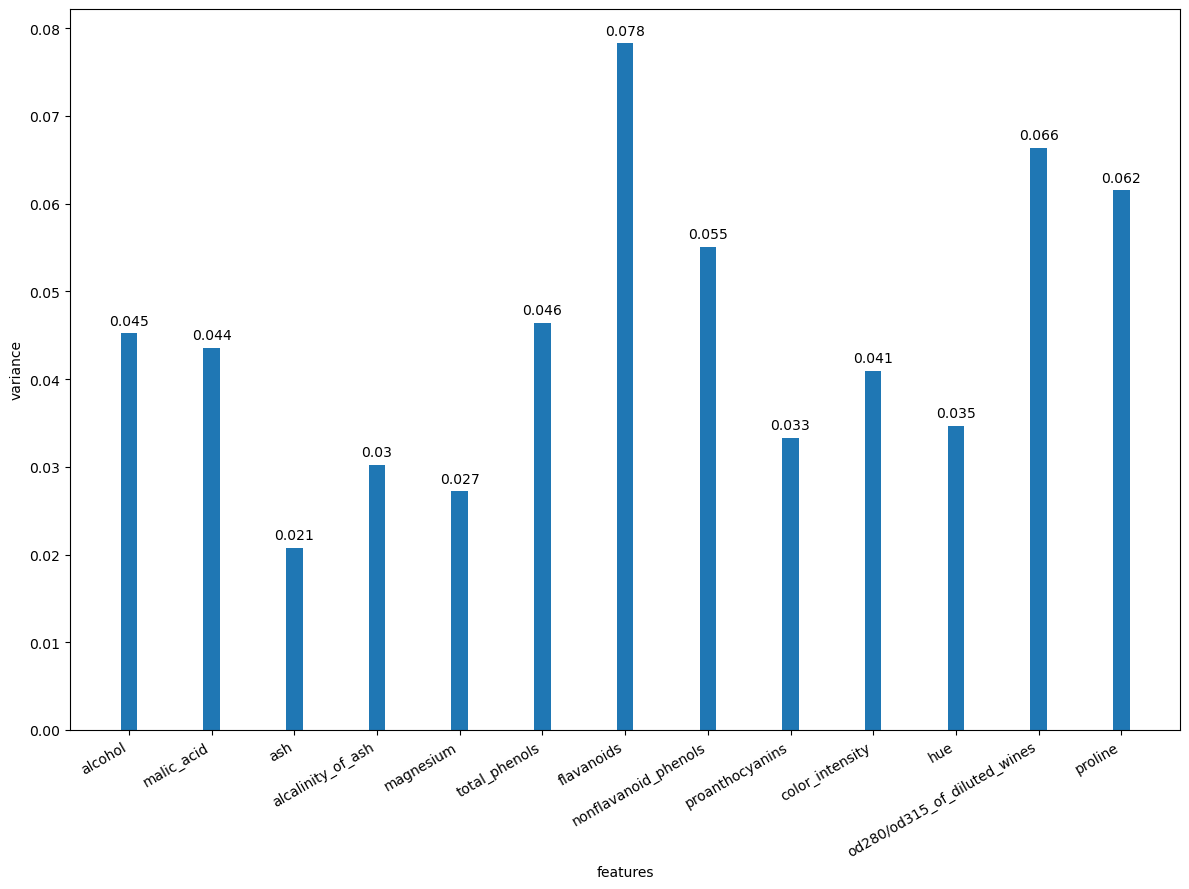

In [20]:
fig,ax= plt.subplots()

x= x_train_v1.columns
y= scaled_x_train_v1.var(axis= 0)

ax.bar(x,y, width=0.2)
ax.set_xlabel('features')
ax.set_ylabel('variance')
#ax.set_ylim(0, 0.1)

for index, value in enumerate(y):
    plt.text(x=index, y=value + 0.001, s= str(round(value,3)), ha='center')

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [21]:
# Now at this point, we need to decide what features we want to drop and which we want to keep
# hence,ill set my threshold to 0.03. ash and magnesium will be dropped because those are the two variables
# with the lowest variance

In [22]:
sel_x_train_v1= x_train_v1.drop(['ash','magnesium'], axis=1)
sel_x_test_v1= x_test_v1.drop(['ash','magnesium'], axis= 1)

#Now once we've selected our features, we are going to fit the model again

gbc.fit(sel_x_train_v1, y_train_v1)
var_preds= gbc.predict(sel_x_test_v1)
f1_score_var= round(f1_score(y_test_v1, var_preds, average= 'weighted'),3)

print(f1_score_var)

0.963


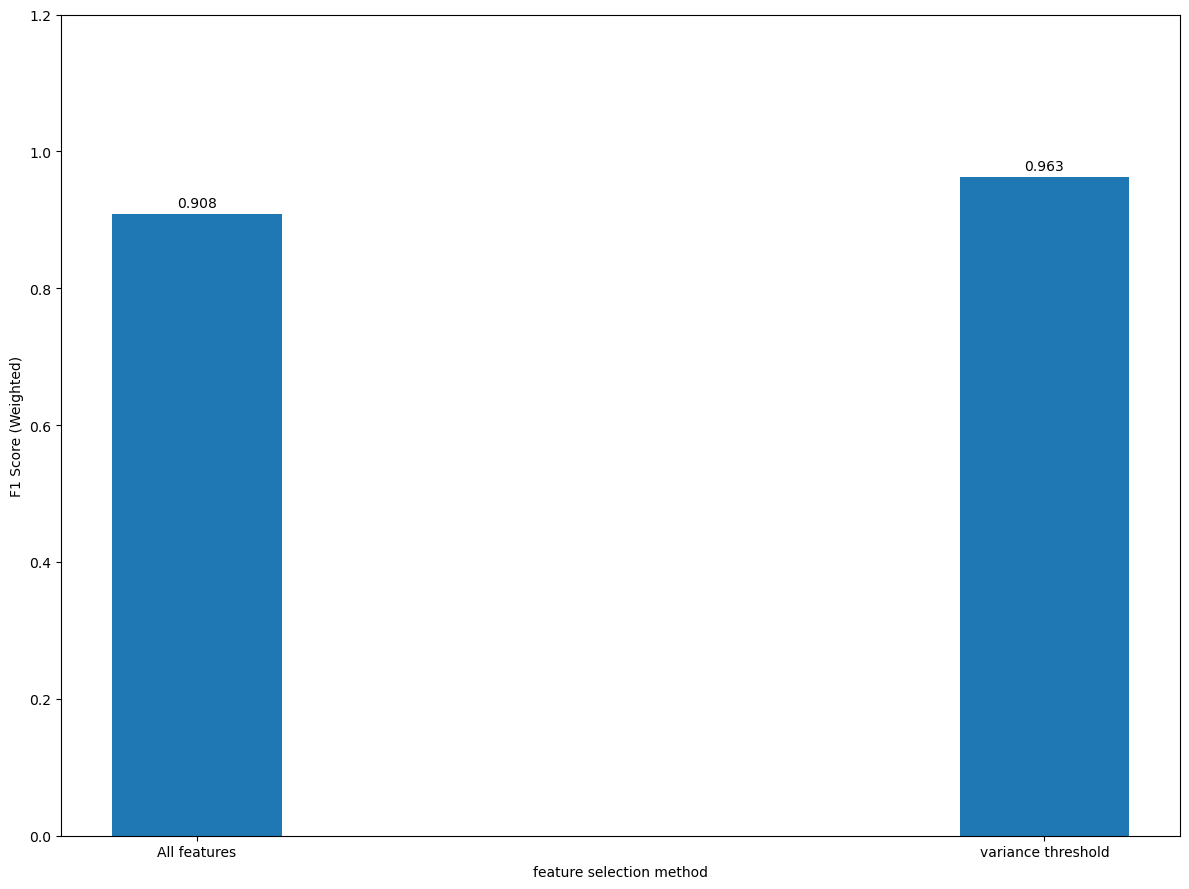

In [23]:
# Just to plot a bar chart to show the info nicer

fig,ax= plt.subplots ()

x= ['All features','variance threshold']
y= [f1_score_all, f1_score_var]

ax.bar(x,y, width=0.2)
ax.set_xlabel('feature selection method')
ax.set_ylabel('F1 Score (Weighted)')
ax.set_ylim(0, 1.2)

for index, value in enumerate (y):
    plt.text(x=index, y=value + 0.01, s= str(round(value, 3)), ha='center')

plt.tight_layout()
plt.show()

In [24]:
# We can now see an improvement in the model by just dropping two features performance

2- K-Best Features Method

Use a measure of importance to select the top k features. 
This method involves calculating the importance of all the features and then tells the algorithm to select the 
top important performance features

In [26]:
#K- Best Features

x_train_v2, x_test_v2, y_train_v2, y_test_v2= x_train.copy(), x_test.copy(), y_train.copy(), y_test.copy()

In [27]:
from sklearn.feature_selection import SelectKBest 
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import f1_score

#First am going to write a for loop to try out a list of possibilities but ill start with a list

f1_score_list= []

for k in range (1,14):
    selector= SelectKBest(mutual_info_classif, k= k)
    selector.fit(x_train_v2, y_train_v2)

    sel_x_train_v2= selector.transform(x_train_v2)
    sel_x_test_v2= selector.transform(x_test_v2)

    gbc.fit(sel_x_train_v2, y_train_v2)
    kbest_preds= gbc.predict(sel_x_test_v2)

    f1_score_kbest= round(f1_score(y_test_v2, kbest_preds, average= 'weighted'),3)
    f1_score_list.append(f1_score_kbest)

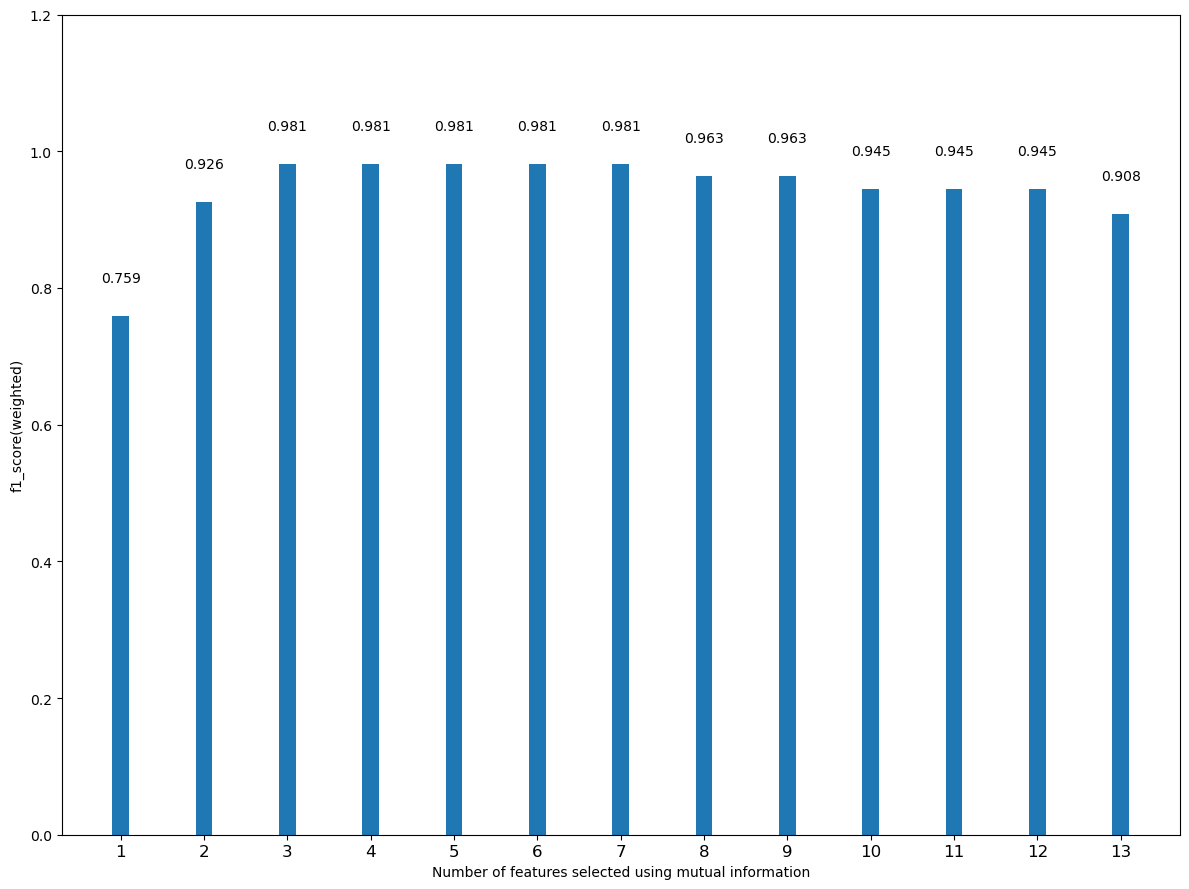

In [28]:
fig, ax= plt.subplots()
x= np.arange(1,14)
y= f1_score_list

ax.bar(x,y, width= 0.2)
ax.set_xlabel('Number of features selected using mutual information')
ax.set_ylabel('f1_score(weighted)')
ax.set_ylim(0, 1.2)
ax.set_xticks(np.arange(1,14))
ax.set_xticklabels(np.arange(1,14), fontsize= 12)

for i, v in enumerate(y):
    plt.text(x= i + 1, y= v + 0.05, s= str(v), ha='center')

plt.tight_layout()
plt.show()

In [29]:
# If you are curious to know the features we selected, there's a way to check

selector= SelectKBest(mutual_info_classif, k=3)
selector.fit(x_train_v2, y_train_v2)

selected_feature_mask= selector.get_support()

selected_features= x_train_v2.columns[selected_feature_mask]

selected_features

Index(['flavanoids', 'color_intensity', 'proline'], dtype='object')

3- Recursive Feature Elimination (RFE)

It uses the model to compute the importance of the feature (tree-based models).
In RFE, all the features is fed into the algorithm. using the model, compute the feature importance and
remove the weakest variable, Check if the number of features is greater than the threshold k



In [31]:
# Recursive Feature Elimination (RFE)

x_train_v3, x_test_v3, y_train_v3, y_test_v3= x_train.copy(), x_test.copy(), y_train.copy(), y_test.copy()

In [32]:
# In this case, we would be using the model to calculate the importance

from sklearn.feature_selection import RFE

rfe_f1_score_list= []

for k in range (1, 14):
    RFE_selector= RFE(estimator= gbc, n_features_to_select= k, step=1)
    RFE_selector.fit(x_train_v3, y_train_v3)

    sel_x_train_v3= RFE_selector.transform(x_train_v3)
    sel_x_test_v3= RFE_selector.transform(x_test_v3)

    gbc.fit(sel_x_train_v3, y_train_v3)
    RFE_preds= gbc.predict(sel_x_test_v3)

    f1_score_rfe= round(f1_score(y_test_v3, RFE_preds, average='weighted'),3)

    rfe_f1_score_list.append(f1_score_rfe)

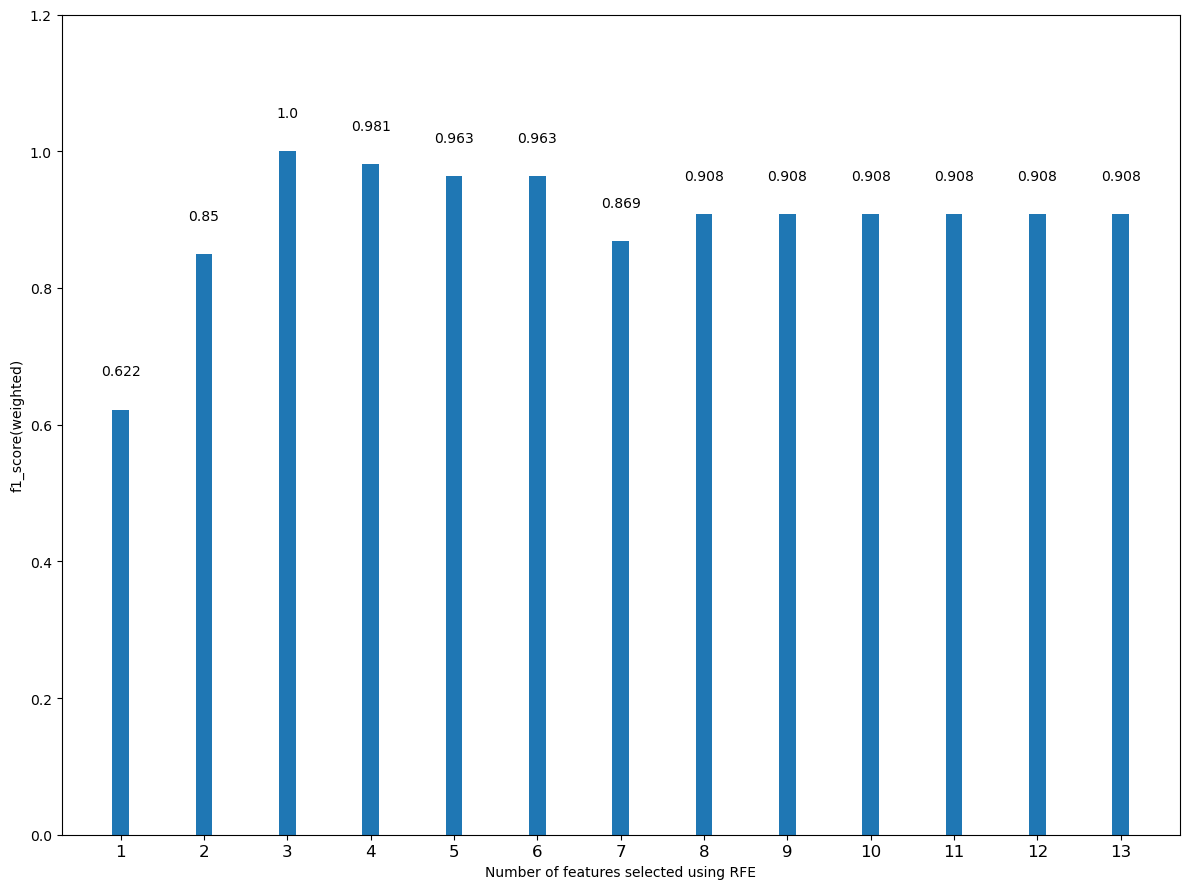

In [33]:
fig, ax= plt.subplots()

x= np.arange(1, 14)
y= rfe_f1_score_list

ax.bar(x,y, width= 0.2)
ax.set_xlabel('Number of features selected using RFE')
ax.set_ylabel('f1_score(weighted)')
ax.set_ylim(0, 1.2)
ax.set_xticks(np.arange(1, 14))
ax.set_xticklabels(np.arange(1, 14), fontsize=12)

for i, v in enumerate(y):
    plt.text(x=i + 1, y= v + 0.05, s= str(v), ha='center')

plt.tight_layout()
plt.show()

In [34]:
RFE_selector= RFE(estimator= gbc, n_features_to_select= 3, step=10)
RFE_selector.fit(x_train_v3, y_train_v3)

selected_features_mask= RFE_selector.get_support()
selected_features= x_train_v3.columns[selected_features_mask]

selected_features

Index(['color_intensity', 'od280/od315_of_diluted_wines', 'proline'], dtype='object')

4- Boruta

A feature selection algorithm where we do not need to set a subjective threshold


Boruta:
1. Create shadow features: randomly shuffled version of each feature
2. Compute the importance of each shadow feature- the highest score becomes our threshold
3. if the importance of the original feature is higher than the threshold; keep otherwise discard

In [36]:
# Boruta

x_train_v4, x_test_v4, y_train_v4, y_test_v4= x_train.copy(), x_test.copy(), y_train.copy(), y_test.copy()

In [ ]:
!pip install Boruta

In [63]:
from boruta import BorutaPy

boruta_selector= BorutaPy(gbc, random_state= 42)

boruta_selector.fit(x_train_v4.values, y_train_v4.values.ravel())

sel_X_train_v4= boruta_selector.transform(x_train_v4.values)
sel_x_test_v4= boruta_selector.transform(x_test_v4.values)

gbc.fit(sel_X_train_v4, y_train_v4)

boruta_preds= gbc.predict(sel_x_test_v4)

boruta_f1_score= round(f1_score(y_test_v4, boruta_preds, average= 'weighted'),3)
print("Boruta F1-score:", boruta_f1_score)

Boruta F1-score: 0.982


In [69]:
selected_features_mask= boruta_selector.support_

selected_features= x_train_v4.columns[selected_features_mask]

selected_features

Index(['malic_acid', 'ash', 'magnesium', 'flavanoids', 'proanthocyanins',
       'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline'],
      dtype='object')

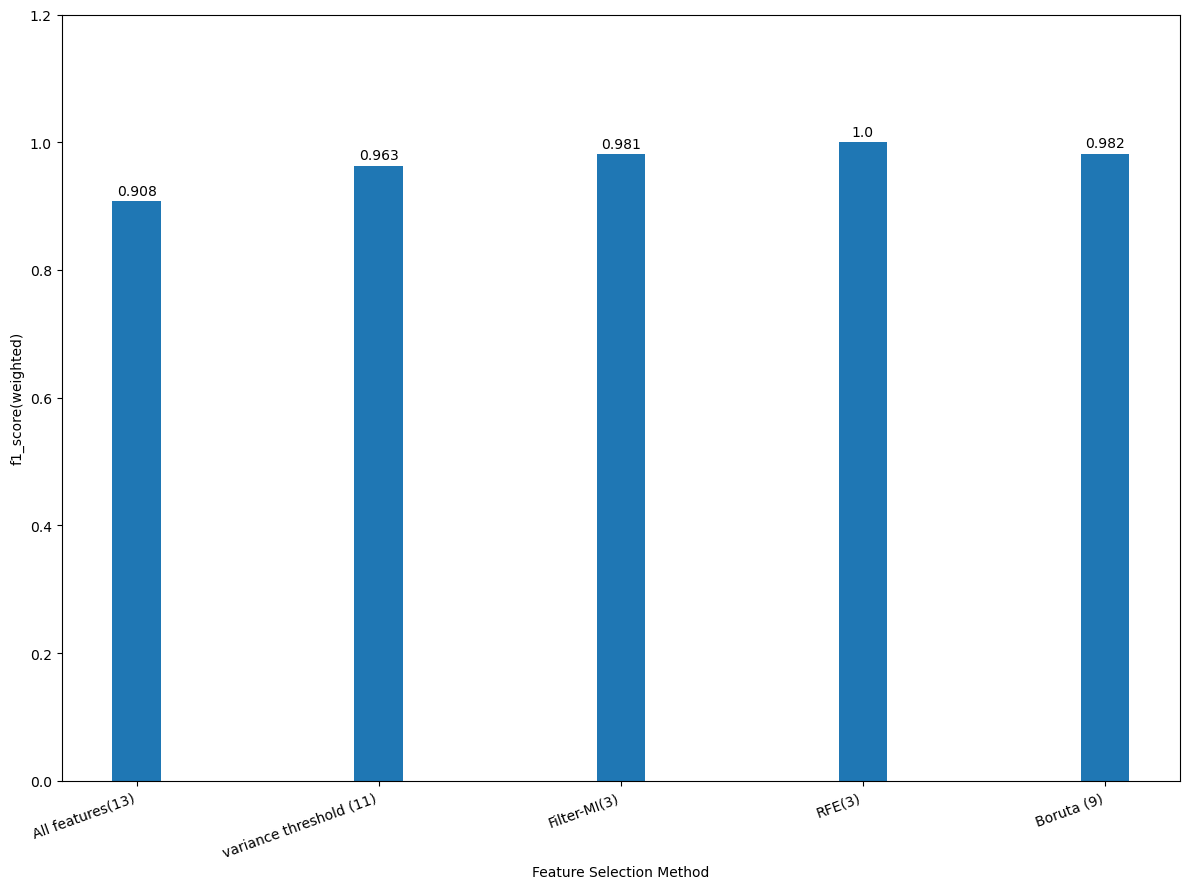

In [79]:
fig, ax= plt.subplots()

x = ['All features(13)', 'variance threshold (11)', 'Filter-MI(3)', 'RFE(3)', 'Boruta (9)']
y= [f1_score_all, f1_score_var, 0.981, 1.0, boruta_f1_score]

ax.bar(x,y, width= 0.2)
ax.set_xlabel('Feature Selection Method')
ax.set_ylabel('f1_score(weighted)')
ax.set_ylim(0, 1.2)

for i, v in enumerate(y):
    plt.text(x=i, y= v + 0.01, s=str(v), ha= 'center')

plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()